In [1]:
# @title Default title text
!pip install pyspark

In [2]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("BigDataSalesAnalytics")
    .master("local[*]")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("ERROR")

print("Spark Version:", spark.version)
print("Spark application started successfully!")

Spark Version: 4.0.4
Spark application started successfully!


In [3]:
import random
from datetime import date, timedelta

random.seed(42)

products = [
    ("Laptop", "Electronics", 55000),
    ("Mobile", "Electronics", 15000),
    ("Headphones", "Electronics", 2000),
    ("Chair", "Furniture", 4000),
    ("Table", "Furniture", 8000),
    ("Notebook", "Stationery", 100),
]

regions = ["Hyderabad", "Chennai", "Bangalore", "Mumbai", "Delhi"]

start_date = date(2025, 1, 1)
records = []

for i in range(1, 10001):
    product, category, price = random.choice(products)

    records.append((
        i,
        product,
        category,
        random.choice(regions),
        random.randint(1, 5),
        float(price),
        str(start_date + timedelta(days=random.randint(0, 364)))
    ))

columns = [
    "order_id", "product", "category", "region",
    "quantity", "price", "order_date"
]

sales_df = spark.createDataFrame(records, columns)

print("Total records:", sales_df.count())
sales_df.show(10, truncate=False)
sales_df.printSchema()


Total records: 10000
+--------+--------+-----------+---------+--------+-------+----------+
|order_id|product |category   |region   |quantity|price  |order_date|
+--------+--------+-----------+---------+--------+-------+----------+
|1       |Notebook|Stationery |Hyderabad|1       |100.0  |2025-05-21|
|2       |Mobile  |Electronics|Chennai  |2       |15000.0|2025-02-22|
|3       |Notebook|Stationery |Delhi    |1       |100.0  |2025-10-30|
|4       |Chair   |Furniture  |Hyderabad|1       |4000.0 |2025-02-17|
|5       |Mobile  |Electronics|Chennai  |5       |15000.0|2025-11-05|
|6       |Laptop  |Electronics|Delhi    |2       |55000.0|2025-11-29|
|7       |Notebook|Stationery |Delhi    |4       |100.0  |2025-04-23|
|8       |Chair   |Furniture  |Delhi    |3       |4000.0 |2025-01-04|
|9       |Mobile  |Electronics|Mumbai   |3       |15000.0|2025-05-23|
|10      |Mobile  |Electronics|Chennai  |3       |15000.0|2025-02-22|
+--------+--------+-----------+---------+--------+-------+----------+

In [4]:
from pyspark.sql.functions import (
    col, round as spark_round, to_date
)

clean_df = (
    sales_df
    .dropDuplicates(["order_id"])
    .filter(
        col("quantity").isNotNull()
        & col("price").isNotNull()
        & (col("quantity") > 0)
        & (col("price") >= 0)
    )
    .withColumn("order_date", to_date("order_date"))
    .withColumn(
        "revenue",
        spark_round(col("quantity") * col("price"), 2)
    )
)

print("Cleaned records:", clean_df.count())
clean_df.show(10, truncate=False)

Cleaned records: 10000
+--------+--------+-----------+---------+--------+-------+----------+--------+
|order_id|product |category   |region   |quantity|price  |order_date|revenue |
+--------+--------+-----------+---------+--------+-------+----------+--------+
|1       |Notebook|Stationery |Hyderabad|1       |100.0  |2025-05-21|100.0   |
|2       |Mobile  |Electronics|Chennai  |2       |15000.0|2025-02-22|30000.0 |
|3       |Notebook|Stationery |Delhi    |1       |100.0  |2025-10-30|100.0   |
|4       |Chair   |Furniture  |Hyderabad|1       |4000.0 |2025-02-17|4000.0  |
|5       |Mobile  |Electronics|Chennai  |5       |15000.0|2025-11-05|75000.0 |
|6       |Laptop  |Electronics|Delhi    |2       |55000.0|2025-11-29|110000.0|
|7       |Notebook|Stationery |Delhi    |4       |100.0  |2025-04-23|400.0   |
|8       |Chair   |Furniture  |Delhi    |3       |4000.0 |2025-01-04|12000.0 |
|9       |Mobile  |Electronics|Mumbai   |3       |15000.0|2025-05-23|45000.0 |
|10      |Mobile  |Electronic

In [7]:
clean_df.createOrReplaceTempView("sales")

spark.sql("""
    SELECT
        COUNT(*) AS total_orders,
        ROUND(SUM(quantity), 0) AS total_items,
        ROUND(SUM(revenue), 2) AS total_revenue,
        ROUND(AVG(revenue), 2) AS average_order_revenue
    FROM sales
""").show()
region_sales = spark.sql("""
    SELECT
        region,
        COUNT(*) AS total_orders,
        ROUND(SUM(revenue), 2) AS total_revenue
    FROM sales
    GROUP BY region
    ORDER BY total_revenue DESC
""")

region_sales.show(truncate=False)
product_sales = spark.sql("""
    SELECT
        product,
        SUM(quantity) AS total_quantity,
        ROUND(SUM(revenue), 2) AS total_revenue
    FROM sales
    GROUP BY product
    ORDER BY total_revenue DESC
""")

product_sales.show(truncate=False)
daily_sales = spark.sql("""
    SELECT
        order_date,
        ROUND(SUM(revenue), 2) AS daily_revenue
    FROM sales
    GROUP BY order_date
    ORDER BY order_date
""")

daily_sales.show(10, truncate=False)


+------------+-----------+-------------+---------------------+
|total_orders|total_items|total_revenue|average_order_revenue|
+------------+-----------+-------------+---------------------+
|       10000|      30045|   4.108302E8|             41083.02|
+------------+-----------+-------------+---------------------+

+---------+------------+-------------+
|region   |total_orders|total_revenue|
+---------+------------+-------------+
|Hyderabad|2085        |8.64171E7    |
|Chennai  |2031        |8.62202E7    |
|Delhi    |1966        |8.11414E7    |
|Bangalore|1872        |8.10729E7    |
|Mumbai   |2046        |7.59786E7    |
+---------+------------+-------------+

+----------+--------------+-------------+
|product   |total_quantity|total_revenue|
+----------+--------------+-------------+
|Laptop    |4802          |2.6411E8     |
|Mobile    |5064          |7.596E7      |
|Table     |4984          |3.9872E7     |
|Chair     |5153          |2.0612E7     |
|Headphones|4880          |9760000.0  

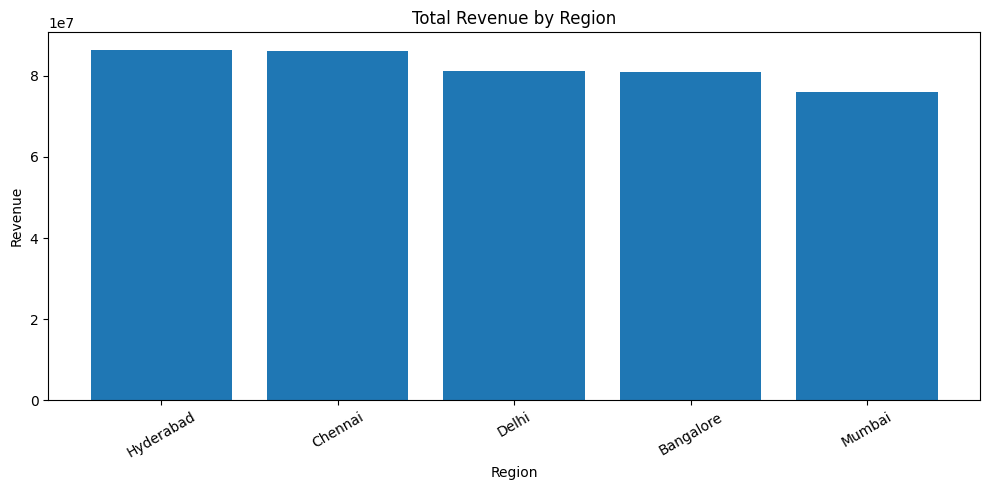

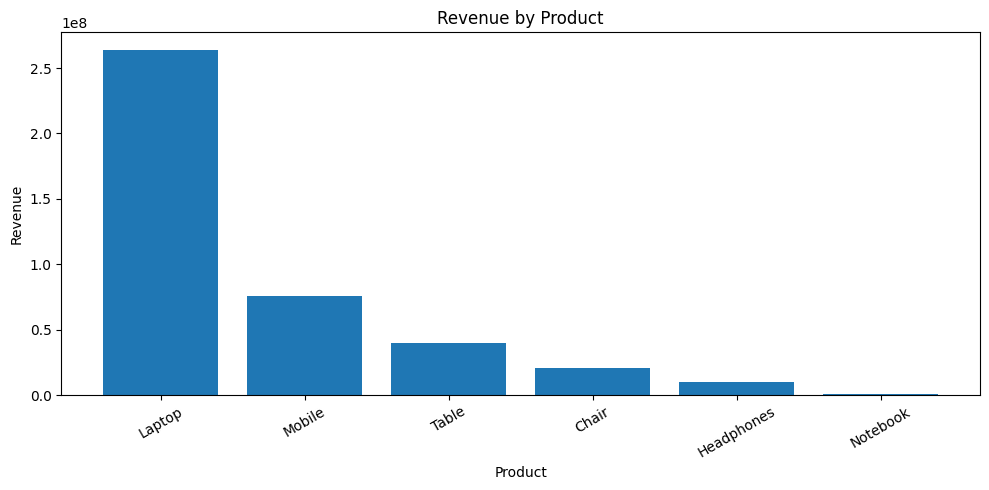

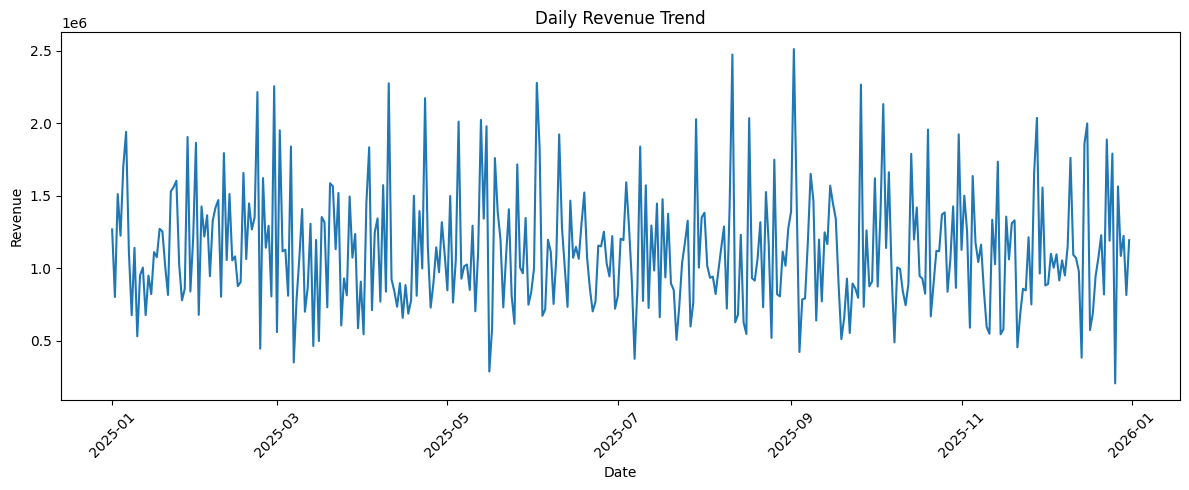

In [8]:
import matplotlib.pyplot as plt

region_pd = region_sales.toPandas()
product_pd = product_sales.toPandas()
daily_pd = daily_sales.toPandas()

# Revenue by region
plt.figure(figsize=(10, 5))
plt.bar(region_pd["region"], region_pd["total_revenue"])
plt.title("Total Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Revenue")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Revenue by product
plt.figure(figsize=(10, 5))
plt.bar(product_pd["product"], product_pd["total_revenue"])
plt.title("Revenue by Product")
plt.xlabel("Product")
plt.ylabel("Revenue")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Daily revenue trend
plt.figure(figsize=(12, 5))
plt.plot(daily_pd["order_date"], daily_pd["daily_revenue"])
plt.title("Daily Revenue Trend")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [9]:
import os

os.makedirs("/content/output", exist_ok=True)

region_sales.toPandas().to_csv(
    "/content/output/region_sales.csv", index=False
)

product_sales.toPandas().to_csv(
    "/content/output/product_sales.csv", index=False
)

daily_sales.toPandas().to_csv(
    "/content/output/daily_sales.csv", index=False
)

print("Analytics reports saved successfully!")


Analytics reports saved successfully!


In [10]:
from google.colab import files
files.download("/content/output/region_sales.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>